### Concepts from proficiency.why as supervision for video-only proficiency

Why-CCA (`why_cca_cv.ipynb`) used each why as one mean-pooled embedding. Its video subspace beat random and top-PCA
subspaces but only tied label PLS: one pooled vector mostly carries "good vs bad", which the level and rating already
give. Here the whys are broken into **concepts** (which aspects the expert judged, and whether well or poorly), so each
take gets ~13 targets instead of one:

1. **Concept labels (text only).** A vocabulary of 8 generic concepts (fluency, control, technique, pace, confidence,
   knowledge, outcome, power) plus 5-7 per scenario was drafted from a reading of *training* whys only. Zero-shot
   Qwen3.5-4B (4-bit, thinking off) reads each why and each concept and answers *good / mixed / poor / unmentioned*;
   the four answer-token probabilities are kept (no generation). Concept score = P(good) - P(poor), averaged over a
   take's experts; mention = 1 - P(unmentioned).
2. **Text check (ceiling).** Do the concept scores, from the held-out take's own whys, predict the level as well as
   the rating or the why embedding do? This needs the text at test time, so it is a ceiling, not a video result.
3. **Video only.** Three ways to use the concepts while fitting, with only video at inference:
   * **concept PLS**: the 16-d video subspace that best predicts the concept scores, then the usual probe;
   * **concept + label PLS**: same, with the level one-hot and rating added to the targets (do concepts add to labels?);
   * **concept bottleneck**: ridge from video (PCA-64) to each concept, then level from the *predicted* concepts.
     The level probe is fit on cross-fitted concept predictions (inner 5-fold split by participant), so it sees
     concept predictions as noisy as the held-out ones.
4. Compared with scenario only, the full features, label PLS and why-CCA (why only), in the exact folds of
   `why_cca_cv.ipynb`: 4 x 5-fold CV over all 1,338 takes split by participant, participant-bootstrap intervals.
   Everything that learns from data is refit inside each fold on the fitting takes; held-out takes contribute only
   their video (except the text ceilings).
   Two metrics: 4-class accuracy (logistic probe) and an **ordinal** one, ridge regression on the level scored by the
   held-out Spearman with the level after removing each scenario's mean from both (knowing the scenario earns
   nothing). A **duration-only** control (log clip length per scenario) checks that the video isn't just clip length.
5. **Which concepts are visible?** Held-out Spearman between each concept's video prediction and its text score.

In [1]:
import ast
import json
from collections import Counter, defaultdict
from pathlib import Path

import av
import numpy as np

# Same takes as the earlier idea_1 notebooks: video and transcribed expert commentary, train / SkillFormer test split.
DATA_ROOT = next(
    p / "data" for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "annotations").is_dir()
)
ANNOTATION_ROOT = DATA_ROOT / "annotations"
COMMENTARY_ROOT = ANNOTATION_ROOT / "expert_commentary"
WINDOW_FPS = 1

LEVELS = {
    "Novice": 1,
    "Early Expert": 2,
    "Intermediate Expert": 3,
    "Late Expert": 4,
}

def take_name(m):
    return m["video_paths"]["ego"].split("/")[1]

def video_path(m):
    parts = m["video_paths"]["ego"].split("/")
    parts[-1:-1] = ["downscaled", "448"]
    return DATA_ROOT.joinpath(*parts)

def has_commentary(take):
    """Whether any expert recorded transcribed commentary on the take (the take set of the earlier notebooks)."""
    for data_path in (COMMENTARY_ROOT / take).rglob("data.json"):
        transcript_path = data_path.parent / "transcriptions.json"
        if not transcript_path.exists():
            continue
        data = json.loads(data_path.read_text(encoding="utf-8"))
        transcripts = json.loads(transcript_path.read_text(encoding="utf-8"))
        if any(transcripts.get(a.get("recording_path"), {}).get("text", "").strip() for a in data.get("annotations", [])):
            return True
    return False

def num_seconds(path):
    """Number of 1 FPS frames decode_1fps() gets from the video (frames 0, 30, 60, ... at 30 FPS)."""
    with av.open(str(path)) as container:
        stream = container.streams.video[0]
        step = round(float(stream.average_rate) / WINDOW_FPS)
        return (stream.frames - 1) // step + 1

with open("models/SkillFormer/annotation_test.jsonl", encoding="utf-8") as file:
    test_takes = {json.loads(line)["video_paths"][0].split("/")[1] for line in file}

def split_clips(split):
    annotation_file = "proficiency_demonstrator_train.json" if split == "train" else "proficiency_demonstrator_val.json"
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        metadata = json.load(file)["annotations"]
    clips = []
    for m in metadata:
        if split == "test" and take_name(m) not in test_takes:
            continue
        if not video_path(m).exists() or not has_commentary(take_name(m)):
            continue
        clips.append({"take_name": take_name(m), "scenario": m["scenario_name"], "score": LEVELS[m["proficiency_score"]],
                      "participant": m["origin_participant_id"], "video": str(video_path(m)),
                      "seconds": num_seconds(video_path(m))})
    return clips

clips_by_split = {split: split_clips(split) for split in ("train", "test")}
clips = clips_by_split["test"]
clip_of = {clip["take_name"]: clip for split_list in clips_by_split.values() for clip in split_list}
for split, split_list in clips_by_split.items():
    print(f"{split}: {len(split_list)} takes, {sum(c['seconds'] for c in split_list) / 3600:.1f} h of video")

# Good executions (polarity 1) and tips for improvement (polarity 0) of those takes. Each entry's "list" is a Python
# list literal of sentences (NaN for a few blank entries, which are dropped).
POLARITIES = {"good_executions": (1, "Good execution"), "tips_for_improvement": (0, "Tip for improvement")}

def entry_sentences(entry):
    if not isinstance(entry.get("list"), str):
        return []
    try:
        items = ast.literal_eval(entry["list"])
    except (ValueError, SyntaxError):
        items = [entry["list"]]
    return [s.strip() for s in (items if isinstance(items, list) else [items]) if isinstance(s, str) and s.strip()]

demonstration = {}
for annotation_file in ("proficiency_demonstration_train.json", "proficiency_demonstration_val.json"):
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        demonstration.update({take_name(m): m for m in json.load(file)["annotations"]})

moments = []
for split, split_list in clips_by_split.items():
    for clip in split_list:
        m = demonstration.get(clip["take_name"])
        for key, (polarity, tag) in POLARITIES.items():
            for entry in (m or {}).get(key, []):
                sentences = entry_sentences(entry)
                if sentences:
                    moments.append({"split": split, "take_name": clip["take_name"], "scenario": clip["scenario"],
                                    "polarity": polarity, "time": float(entry["video_time"]), "expert": entry["expert_uid"],
                                    "text": f"{tag}: {' '.join(sentences)}"})
covered = {m["take_name"] for m in moments}
for split in ("train", "test"):
    split_moments = [m for m in moments if m["split"] == split]
    print(f"{split}: {sum(c['take_name'] in covered for c in clips_by_split[split])} takes with moments, "
          f"{sum(m['polarity'] for m in split_moments)} good executions, {sum(1 - m['polarity'] for m in split_moments)} tips; "
          f"scenarios {dict(Counter(m['scenario'] for m in split_moments))}")

train: 1174 takes, 36.3 h of video
test: 164 takes, 4.9 h of video
train: 371 takes with moments, 8241 good executions, 8326 tips; scenarios {'Cooking': 5033, 'Basketball': 7358, 'Dance': 1841, 'Music': 2228, 'Soccer': 107}
test: 61 takes with moments, 1315 good executions, 1161 tips; scenarios {'Basketball': 1315, 'Cooking': 481, 'Music': 264, 'Dance': 416}


In [2]:
# Every expert's rating and why for each take.
def take_whys(take):
    whys = []
    for path in sorted((COMMENTARY_ROOT / take).glob("*/data.json")):
        proficiency = json.loads(path.read_text(encoding="utf-8")).get("proficiency") or {}
        why = (proficiency.get("why") or "").strip()
        if not why:
            continue
        try:
            rating = float(proficiency.get("rating"))
        except (TypeError, ValueError):
            rating = None
        whys.append({"expert": path.parent.name, "why": why, "rating": rating})
    return whys

pairs = []
for split, split_list in clips_by_split.items():
    for clip in split_list:
        for w in take_whys(clip["take_name"]):
            rated = f"Rating {w['rating']:g}/10: {w['why']}" if w["rating"] is not None else w["why"]
            pairs.append({"split": split, "take_name": clip["take_name"], "scenario": clip["scenario"],
                          "participant": clip["participant"], "score": clip["score"], "rating": w["rating"],
                          "rated": rated, "plain": w["why"]})
for split in ("train", "test"):
    split_pairs = [p for p in pairs if p["split"] == split]
    print(f"{split}: {len(split_pairs)} whys over {len({p['take_name'] for p in split_pairs})} of "
          f"{len(clips_by_split[split])} takes; {sum(p['rating'] is None for p in split_pairs)} without a rating")

train: 4344 whys over 1174 of 1174 takes; 83 without a rating
test: 660 whys over 164 of 164 takes; 11 without a rating


In [3]:
# Concept vocabulary for proficiency.why, drafted from a reading of training whys only.
ACTIVITY = {"Basketball": "basketball", "Cooking": "cooking", "Dance": "dance", "Music": "music (playing an instrument)",
            "Rock Climbing": "bouldering (rock climbing)", "Soccer": "soccer"}

GENERIC = {
    "fluency": "flow and continuity (executing smoothly without stopping, hesitating or getting stuck)",
    "control": "control, balance and precision of movement",
    "technique": "technique and form",
    "pace": "speed, pace and efficiency",
    "confidence": "confidence and comfort with the task",
    "knowledge": "knowledge of the task (knowing the steps, rules, choreography, route or piece)",
    "outcome": "success of the outcome (made shots, finished route, correct notes, good final dish)",
    "power": "power, energy and athleticism",
}

SPECIFIC = {
    "Basketball": {
        "footwork": "footwork and steps into the shot",
        "shooting form": "shooting form and release (release point, follow-through, hand placement)",
        "ball handling": "ball handling and dribbling",
        "lift": "lift and explosiveness",
        "weak hand": "use of the weaker hand",
    },
    "Cooking": {
        "knife skills": "knife skills",
        "heat control": "heat and temperature control",
        "workspace": "organization and cleanliness of the workspace (mise en place)",
        "recipe steps": "following the recipe and the order of steps",
        "food result": "quality of the finished food (doneness, texture, taste)",
        "safety": "kitchen safety and hygiene",
    },
    "Dance": {
        "rhythm": "rhythm and musicality (staying on the beat)",
        "memory": "memory of the choreography",
        "arms": "use of the arms and upper body",
        "grounding": "balance and grounding",
        "dynamics": "energy, dynamics and sharpness of movement",
        "clarity": "clarity and precision of the steps",
    },
    "Music": {
        "pitch": "pitch accuracy and intonation (correct notes)",
        "tempo": "rhythm and steadiness of tempo",
        "tone": "tone quality and articulation",
        "musicality": "musicality, phrasing and expression",
        "hand position": "hand position and posture",
    },
    "Rock Climbing": {
        "progress": "progress on the route (how far they got, whether they sent it)",
        "footwork": "footwork and foot placement",
        "tension": "body tension (keeping the feet on the wall)",
        "hips": "hip and body positioning",
        "energy use": "efficient use of strength (not over-relying on the arms)",
        "dynamic moves": "dynamic moves and momentum",
        "route reading": "route reading and decision making",
    },
    "Soccer": {
        "ball control": "ball control and touch",
        "weak foot": "use of the weaker foot",
        "striking": "striking technique and shot accuracy",
        "agility": "speed and change of direction",
        "posture": "body posture and balance over the ball",
    },
}

def concepts_for(scenario):
    return {**GENERIC, **SPECIFIC[scenario]}

ANSWERS = ["good", "mixed", "poor", "unmentioned"]

def concept_prompt(scenario, why, description):
    return (f"Here is an expert's feedback on a person's {ACTIVITY[scenario]} performance:\n\n\"{why}\"\n\n"
            f"According to this feedback, how was the person's {description}? "
            f"Reply with exactly one word: good, mixed, poor, or unmentioned.")


VOCABULARY_SIGNATURE = json.dumps([GENERIC, SPECIFIC, ANSWERS, concept_prompt("Dance", "WHY", "DESCRIPTION")])
COLUMNS = [("all", c) for c in GENERIC] + [(s, c) for s in SPECIFIC for c in SPECIFIC[s]]
COLUMN = {key: i for i, key in enumerate(COLUMNS)}
print(f"{len(GENERIC)} generic + {sum(map(len, SPECIFIC.values()))} scenario-specific concepts; "
      f"{sum(len(concepts_for(p['scenario'])) for p in pairs)} (why, concept) questions")

8 generic + 34 scenario-specific concepts; 69134 (why, concept) questions


In [4]:
import torch
from tqdm.auto import tqdm

# Concept labels: one forward pass per (why, concept); keep the probabilities of the four answer words' first tokens.
EMBEDDING_DIR = Path("embeddings")
CONCEPT_CACHE = EMBEDDING_DIR / "qwen35_why_concepts.pt"
cache = torch.load(CONCEPT_CACHE) if CONCEPT_CACHE.exists() else {"vocabulary": VOCABULARY_SIGNATURE, "scores": {}}
assert cache["vocabulary"] == VOCABULARY_SIGNATURE, "vocabulary changed; delete the cache"
todo = sorted({(p["scenario"], p["plain"]) for p in pairs} - set(cache["scores"]))
print(f"{len(todo)} whys to label")
if todo:
    from transformers import AutoModelForMultimodalLM, AutoProcessor, BitsAndBytesConfig
    model_id = "Qwen/Qwen3.5-4B"
    bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.bfloat16,
                                    bnb_4bit_use_double_quant=True)
    model = AutoModelForMultimodalLM.from_pretrained(model_id, quantization_config=bnb_config, device_map="auto").eval()
    tokenizer = AutoProcessor.from_pretrained(model_id).tokenizer
    tokenizer.padding_side = "right"
    answer_ids = [tokenizer.encode(a, add_special_tokens=False)[0] for a in ANSWERS]
    assert len(set(answer_ids)) == len(ANSWERS)

    @torch.inference_mode()
    def answer_probabilities(questions):
        texts = [tokenizer.apply_chat_template([{"role": "user", "content": q}], tokenize=False,
                                               add_generation_prompt=True, enable_thinking=False) for q in questions]
        batch = tokenizer(texts, return_tensors="pt", padding=True).to(model.device)
        last = batch["attention_mask"].sum(1) - 1
        keep = torch.unique(last)  # vocabulary logits only at the batch's last-token positions
        with torch.autocast("cuda", dtype=torch.bfloat16):
            logits = model(**batch, logits_to_keep=keep).logits
        return logits[torch.arange(len(texts)), torch.searchsorted(keep, last)][:, answer_ids].float().softmax(-1).cpu()

    BATCH, CHUNK = 16, 400
    for start in tqdm(range(0, len(todo), CHUNK), desc="chunks of whys"):
        keys = todo[start:start + CHUNK]
        questions = [(key, i, concept_prompt(key[0], key[1], d)) for key in keys
                     for i, d in enumerate(concepts_for(key[0]).values())]
        questions.sort(key=lambda q: len(q[2]))  # similar lengths per batch: little padding
        results = defaultdict(dict)
        for b in range(0, len(questions), BATCH):
            chunk = questions[b:b + BATCH]
            for (key, i, _), probabilities in zip(chunk, answer_probabilities([q for _, _, q in chunk])):
                results[key][i] = probabilities
        for key, by_index in results.items():
            cache["scores"][key] = torch.stack([by_index[i] for i in range(len(by_index))])
        torch.save(cache, CONCEPT_CACHE)
    del model
    torch.cuda.empty_cache()

3720 whys to label


W1115 16:38:33.042000 32344 site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


Loading weights:   0%|          | 0/723 [00:00<?, ?it/s]

chunks of whys:   0%|          | 0/10 [00:00<?, ?it/s]

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


In [5]:
from scipy.stats import spearmanr

all_clips = clips_by_split["train"] + clips_by_split["test"]
names = [c["take_name"] for c in all_clips]
position = {name: i for i, name in enumerate(names)}
scores = np.array([c["score"] for c in all_clips])
scenarios = np.array([c["scenario"] for c in all_clips])
participants = np.array([c["participant"] for c in all_clips])
original_test = np.array([c["take_name"] in {t["take_name"] for t in clips_by_split["test"]} for c in all_clips])

def why_vectors(pair):
    """(signed, mention) over COLUMNS for one why; NaN outside the why's scenario."""
    probabilities = cache["scores"][pair["scenario"], pair["plain"]].numpy()
    signed, mention = np.full(len(COLUMNS), np.nan), np.full(len(COLUMNS), np.nan)
    for i, name in enumerate(concepts_for(pair["scenario"])):
        column = COLUMN["all", name] if name in GENERIC else COLUMN[pair["scenario"], name]
        signed[column] = probabilities[i, 0] - probabilities[i, 2]
        mention[column] = 1 - probabilities[i, 3]
    return signed, mention

pair_take = np.array([position[p["take_name"]] for p in pairs])
pair_signed, pair_mention = map(np.array, zip(*[why_vectors(p) for p in pairs]))
pair_rating = np.array([np.nan if p["rating"] is None else p["rating"] for p in pairs])
applicable = np.array([[s in ("all", scenario) for s, _ in COLUMNS] for scenario in scenarios])
take_signed = np.stack([np.nanmean(pair_signed[pair_take == t], 0) for t in range(len(names))])
take_mention = np.stack([np.nanmean(pair_mention[pair_take == t], 0) for t in range(len(names))])
take_signed[~applicable], take_mention[~applicable] = 0, 0  # other scenarios' concepts: 0 (the probe also gets the scenario)
take_rating = np.array([np.nanmean(pair_rating[pair_take == t]) if (~np.isnan(pair_rating[pair_take == t])).any()
                        else np.nan for t in range(len(names))])

def scenario_centered(values, rows):
    out = values.astype(float).copy()
    for s in np.unique(scenarios[rows]):
        r = rows & (scenarios == s)
        out[r] -= np.nanmean(values[r])
    return out

# Sanity: concept scores should track the expert's own rating (never shown to the labeller).
everything = np.ones(len(names), bool)
rated = ~np.isnan(pair_rating)
net = np.nanmean(pair_signed, 1)
take_net = take_signed.sum(1) / applicable.sum(1)
has_rating = ~np.isnan(take_rating)
print(f"why-level net concept score vs the same expert's rating: Spearman {spearmanr(net[rated], pair_rating[rated])[0]:.3f} "
      f"({rated.sum()} whys)")
print(f"take-level net concept score vs level (scenario-centered): Spearman "
      f"{spearmanr(scenario_centered(take_net, everything), scenario_centered(scores, everything))[0]:.3f}")
print(f"take-level mean rating vs level (scenario-centered): Spearman "
      f"{spearmanr(scenario_centered(take_rating, has_rating)[has_rating], scenario_centered(scores, has_rating)[has_rating])[0]:.3f}\n")

concept_table = []
print(f"{'concept':<28}{'takes':>6}{'mentioned':>11}{'mean score':>12}{'rho rating':>12}{'rho level':>11}")
for column, (scope, name) in enumerate(COLUMNS):
    rows = applicable[:, column]
    why_rows = ~np.isnan(pair_signed[:, column]) & rated
    rho_rating = spearmanr(pair_signed[why_rows, column], pair_rating[why_rows])[0]
    rho_level = spearmanr(scenario_centered(take_signed[:, column], rows)[rows], scenario_centered(scores, rows)[rows])[0]
    concept_table.append({"scope": scope, "name": name, "rho_level": rho_level})
    label = f"{name} ({'generic' if scope == 'all' else scope})"
    print(f"{label:<28}{rows.sum():>6}{take_mention[rows, column].mean():>11.2f}{take_signed[rows, column].mean():>+12.2f}"
          f"{rho_rating:>+12.2f}{rho_level:>+11.2f}")

for p in [pairs[i] for i in np.random.default_rng(0).choice(len(pairs), 3, replace=False)]:
    signed, mention = why_vectors(p)
    shown = [f"{COLUMNS[c][1]} {signed[c]:+.2f}" for c in np.argsort(-np.nan_to_num(mention, nan=-1))[:5]]
    print(f"\n[{p['scenario']}, rating {p['rating']}] {p['plain'][:240]}\n   most-mentioned: {'; '.join(shown)}")

why-level net concept score vs the same expert's rating: Spearman 0.810 (4910 whys)
take-level net concept score vs level (scenario-centered): Spearman 0.433
take-level mean rating vs level (scenario-centered): Spearman 0.483

concept                      takes  mentioned  mean score  rho rating  rho level
fluency (generic)             1338       0.58       -0.09       +0.76      +0.40
control (generic)             1338       0.82       +0.07       +0.78      +0.43
technique (generic)           1338       0.86       +0.10       +0.78      +0.43
pace (generic)                1338       0.50       -0.02       +0.76      +0.36
confidence (generic)          1338       0.54       +0.01       +0.74      +0.41
knowledge (generic)           1338       0.78       +0.14       +0.74      +0.43
outcome (generic)             1338       0.73       +0.01       +0.77      +0.41
power (generic)               1338       0.44       +0.02       +0.71      +0.39
footwork (Basketball)          379       0.6

C:\Users\darkn\AppData\Local\Temp\ipykernel_32344\2253772905.py:25: RuntimeWarning: Mean of empty slice
  take_signed = np.stack([np.nanmean(pair_signed[pair_take == t], 0) for t in range(len(names))])
C:\Users\darkn\AppData\Local\Temp\ipykernel_32344\2253772905.py:26: RuntimeWarning: Mean of empty slice
  take_mention = np.stack([np.nanmean(pair_mention[pair_take == t], 0) for t in range(len(names))])


In [6]:
LAYERS = {"early": 8, "middle": 16, "last": 32}
TEXT_LAYER_INDEX = 1  # layer 16, as in why_cca_cv.ipynb
text_cache = torch.load(EMBEDDING_DIR / "qwen35_base_why_text.pt")

def qwen_tile_windows(take, length=20):
    seconds = clip_of[take]["seconds"]
    windows = []
    for start in range(0, seconds, length):
        size = min(length, seconds - start)
        size -= size % 2
        if size >= 2 and (size >= length // 2 or not windows):
            windows.append((start, size))
    return windows

window_cache = torch.load(EMBEDDING_DIR / "qwen35_base_goodtip_windows.pt")
video = {layer: np.stack([torch.stack([window_cache[t][w][i] for w in qwen_tile_windows(t)]).double().mean(0).numpy()
                          for t in names]) for i, layer in enumerate(LAYERS.values())}
del window_cache
pair_scenario = np.array([p["scenario"] for p in pairs])
pair_text = np.stack([text_cache[p["plain"]][TEXT_LAYER_INDEX].double().numpy() for p in pairs])
take_text = np.stack([pair_text[pair_take == t].mean(0) for t in range(len(names))])
print(f"{len(names)} takes, {len(set(participants))} participants, {len(pairs)} whys, {len(COLUMNS)} concept columns")

1338 takes, 185 participants, 5004 whys, 42 concept columns


In [7]:
from sklearn.cross_decomposition import CCA, PLSRegression
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegressionCV, RidgeCV
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

N_REPEATS, N_FOLDS = 4, 5
PCA_DIMS, N_COMPONENTS = 64, 16
ALPHAS = np.logspace(-1, 5, 13)
GENERIC_COLUMNS = [COLUMN["all", c] for c in GENERIC]
CONCEPT_GROUPS = [(GENERIC_COLUMNS, np.ones(len(names), bool))] + \
                 [([COLUMN[s, c] for c in SPECIFIC[s]], scenarios == s) for s in SPECIFIC]

def centered(X, keys, fit):
    """X minus the mean of the fit rows sharing each row's key (overall fit mean for unseen keys)."""
    fit_rows = np.zeros(len(X), bool)
    fit_rows[fit] = True
    overall = X[fit_rows].mean(0)
    means = {k: X[fit_rows & (keys == k)].mean(0) if (fit_rows & (keys == k)).any() else overall for k in np.unique(keys)}
    return X - np.stack([means[k] for k in keys])

def project(x, mean, basis):
    return (x - mean) @ basis @ basis.T

def subspace(pca, model):
    return np.linalg.qr(pca.components_.T @ (model.x_rotations_ / model._x_std[:, None]))[0]

def make_probe():
    return make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=np.logspace(-4, 2, 13), cv=5, max_iter=5000, n_jobs=-1))

def predict_concepts(Z, train, target):
    """Ridge from video PCA scores to scenario-centered concept scores, fit on the train takes where each concept
    applies; scenario-centered predictions for the target takes (0 where the concept doesn't apply)."""
    out = np.zeros((len(target), len(COLUMNS)))
    for columns, rows in CONCEPT_GROUPS:
        fit_rows, target_rows = train[rows[train]], np.flatnonzero(rows[target])
        if len(fit_rows) < 10 or not len(target_rows):
            continue
        Y = centered(take_signed[:, columns], scenarios, fit_rows)
        ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=ALPHAS, alpha_per_target=True)).fit(Z[fit_rows], Y[fit_rows])
        out[np.ix_(target_rows, columns)] = ridge.predict(Z[target[target_rows]])
    return out

hits = defaultdict(lambda: np.full((N_REPEATS, len(names)), np.nan))
predicted = defaultdict(lambda: np.zeros((N_REPEATS, len(names)), int))
continuous = defaultdict(lambda: np.full((N_REPEATS, len(names)), np.nan))  # ridge regression on the level
concept_prediction = {layer: np.zeros((N_REPEATS, len(names), len(COLUMNS))) for layer in LAYERS.values()}
log_duration = np.log([clip_of[t]["seconds"] for t in names])
fold_of = np.zeros((N_REPEATS, len(names)), int)
SCENARIO_NAMES = np.unique(scenarios)

for repeat in range(N_REPEATS):  # same folds as why_cca_cv.ipynb
    folds = StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=repeat).split(np.zeros(len(names)), scores, participants)
    for fold, (fit, held) in enumerate(tqdm(list(folds), desc=f"repeat {repeat + 1}")):
        fold_of[repeat, held] = fold
        encoder = OneHotEncoder(handle_unknown="ignore").fit(scenarios[fit][:, None])
        onehot = encoder.transform(scenarios[:, None]).toarray()

        def run(key, features):
            """4-class logistic probe (accuracy) and ridge regression on the level (ordinal), both on
            [scenario one-hot, features], fit on the fit takes; records the held-out predictions."""
            X = np.hstack([onehot, features])
            prediction = make_probe().fit(X[fit], scores[fit]).predict(X[held])
            predicted[key][repeat, held] = prediction
            hits[key][repeat, held] = prediction == scores[held]
            ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 6, 17))).fit(X[fit], scores[fit])
            continuous[key][repeat, held] = ridge.predict(X[held])

        run("scenario only", np.zeros((len(names), 0)))
        duration = centered(log_duration[:, None], scenarios, fit)
        run("duration only", np.hstack([duration * (scenarios == s)[:, None] for s in SCENARIO_NAMES]))
        # Text ceilings: the held-out take's own whys at test time.
        rating = np.where(np.isnan(take_rating), np.nanmean(take_rating[fit]), take_rating)
        run("text: mean rating", rating[:, None])
        run("text: concepts", np.hstack([take_signed, take_mention]))
        run("text: concepts + rating", np.hstack([take_signed, take_mention, rating[:, None]]))
        text = centered(take_text, scenarios, fit)
        run("text: why embedding", PCA(PCA_DIMS, svd_solver="full").fit(text[fit]).transform(text))

        fit_pairs = np.flatnonzero(np.isin(pair_take, fit))
        concepts_fit = centered(take_signed, scenarios, fit)[fit]
        inner = list(GroupKFold(5).split(fit, groups=participants[fit]))
        for layer in LAYERS.values():
            V = centered(video[layer], scenarios, fit)
            pca_video = PCA(PCA_DIMS, svd_solver="full").fit(V[fit])
            mean, Z = pca_video.mean_, pca_video.transform(V)
            run(f"layer {layer}: full", V)

            Y_label = np.column_stack([np.eye(4)[scores[fit] - 1], rating[fit]])
            pls = PLSRegression(n_components=N_COMPONENTS, scale=True).fit(Z[fit], Y_label)
            run(f"layer {layer}: label PLS", project(V, mean, subspace(pca_video, pls)))
            pls = PLSRegression(n_components=N_COMPONENTS, scale=True).fit(Z[fit], concepts_fit)
            run(f"layer {layer}: concept PLS", project(V, mean, subspace(pca_video, pls)))
            pls = PLSRegression(n_components=N_COMPONENTS, scale=True).fit(Z[fit], np.hstack([concepts_fit, Y_label]))
            run(f"layer {layer}: concept + label PLS", project(V, mean, subspace(pca_video, pls)))

            texts = centered(pair_text, pair_scenario, fit_pairs)
            pca_text = PCA(PCA_DIMS, svd_solver="full").fit(texts[fit_pairs])
            cca = CCA(n_components=N_COMPONENTS, max_iter=2000).fit(Z[pair_take[fit_pairs]], pca_text.transform(texts[fit_pairs]))
            run(f"layer {layer}: why-CCA (why only)", project(V, mean, subspace(pca_video, cca)))

            bottleneck = np.zeros((len(names), len(COLUMNS)))
            for a, b in inner:  # cross-fitted concept predictions for the fit takes
                bottleneck[fit[b]] = predict_concepts(Z, fit[a], fit[b])
            bottleneck[held] = predict_concepts(Z, fit, held)
            concept_prediction[layer][repeat, held] = bottleneck[held]
            run(f"layer {layer}: concept bottleneck", bottleneck)

assert all(not np.isnan(h).any() for h in hits.values())
print(f"{len(hits)} methods x {N_REPEATS} repeats x {len(names)} takes")

repeat 1:   0%|          | 0/5 [00:00<?, ?it/s]

C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


... (56 outputs left out)

C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


24 methods x 4 repeats x 1338 takes


In [8]:
from sklearn.metrics import balanced_accuracy_score

N_BOOTSTRAP = 1000
METHODS = ["full", "label PLS", "why-CCA (why only)", "concept PLS", "concept + label PLS", "concept bottleneck"]
TEXT = ["text: mean rating", "text: why embedding", "text: concepts", "text: concepts + rating"]
per_take = {key: h.mean(0) for key, h in hits.items()}
unique_participants = np.unique(participants)
rows_of = {p: np.flatnonzero(participants == p) for p in unique_participants}
boot = np.random.default_rng(0)
resamples = [np.concatenate([rows_of[p] for p in boot.choice(unique_participants, len(unique_participants))])
             for _ in range(N_BOOTSTRAP)]
SUBGROUPS = {"All": np.ones(len(names), bool), "Original test takes": original_test,
             "Rock Climbing": scenarios == "Rock Climbing"}

def describe(values, rows):
    lo, hi = np.quantile([values[r[rows[r]]].mean() for r in resamples], [0.025, 0.975])
    return values[rows].mean(), lo, hi

def table(keys):
    for key in keys:
        cells = [f"{m:.3f} [{lo:.3f}, {hi:.3f}]" for m, lo, hi in (describe(per_take[key], rows) for rows in SUBGROUPS.values())]
        repeat_accuracy = hits[key].mean(1)
        print(f"{key:<38}" + "".join(f"{c:>30}" for c in cells) + f"   ({repeat_accuracy.min():.3f}-{repeat_accuracy.max():.3f})")

header = f"{'features':<38}" + "".join(f"{f'{g} ({rows.sum()})':>30}" for g, rows in SUBGROUPS.items())
print(f"Held-out accuracy, {N_REPEATS} x {N_FOLDS}-fold CV split by participant [95% participant-bootstrap]; repeat range\n")
print("Text ceilings (the held-out take's own whys at test time)\n" + header)
table(["scenario only"] + TEXT)
print("\nVideo only\n" + header)
table(["scenario only", "duration only"] + [f"layer {layer}: {m}" for layer in LAYERS.values() for m in METHODS])

differences = {}
print("\nConcept methods minus controls, all takes [95% participant-bootstrap]; P(diff <= 0)")
for layer in LAYERS.values():
    for method in ("concept bottleneck", "concept + label PLS", "concept PLS"):
        for other in ["scenario only", f"layer {layer}: full", f"layer {layer}: label PLS", f"layer {layer}: why-CCA (why only)"]:
            diff = per_take[f"layer {layer}: {method}"] - per_take[other]
            boots = np.array([diff[r].mean() for r in resamples])
            differences[layer, method, other.split(": ")[-1]] = (diff.mean(), *np.quantile(boots, [0.025, 0.975]))
            print(f"  layer {layer:<3} {method:<21} vs {other.split(': ')[-1]:<20} {diff.mean():+.3f} "
                  f"[{np.quantile(boots, 0.025):+.3f}, {np.quantile(boots, 0.975):+.3f}]   {np.mean(boots <= 0):.3f}")

print("\nBalanced accuracy, mean over repeats:")
for key in ["scenario only"] + TEXT + [f"layer {layer}: {m}" for layer in LAYERS.values() for m in METHODS]:
    print(f"  {key:<38} {np.mean([balanced_accuracy_score(scores, predicted[key][r]) for r in range(N_REPEATS)]):.3f}")

Held-out accuracy, 4 x 5-fold CV split by participant [95% participant-bootstrap]; repeat range

Text ceilings (the held-out take's own whys at test time)
features                                                  All (1338)     Original test takes (164)           Rock Climbing (413)
scenario only                                   0.400 [0.325, 0.484]          0.405 [0.242, 0.574]          0.293 [0.125, 0.478]   (0.338-0.448)
text: mean rating                               0.464 [0.400, 0.532]          0.441 [0.307, 0.559]          0.314 [0.193, 0.447]   (0.445-0.480)
text: why embedding                             0.424 [0.372, 0.484]          0.438 [0.328, 0.548]          0.268 [0.179, 0.367]   (0.417-0.430)
text: concepts                                  0.449 [0.394, 0.512]          0.451 [0.334, 0.556]          0.272 [0.182, 0.375]   (0.434-0.460)
text: concepts + rating                         0.465 [0.411, 0.527]          0.465 [0.352, 0.571]          0.288 [0.196, 0.393]   (0.45

layer 8: concept PLS                            0.437 [0.372, 0.506]          0.370 [0.254, 0.488]          0.298 [0.189, 0.419]   (0.416-0.448)
layer 8: concept + label PLS                    0.441 [0.384, 0.503]          0.407 [0.294, 0.530]          0.323 [0.224, 0.429]   (0.431-0.449)
layer 8: concept bottleneck                     0.418 [0.361, 0.478]          0.378 [0.280, 0.478]          0.315 [0.214, 0.428]   (0.390-0.443)
layer 16: full                                  0.415 [0.365, 0.468]          0.387 [0.287, 0.506]          0.303 [0.225, 0.389]   (0.404-0.421)
layer 16: label PLS                             0.426 [0.368, 0.487]          0.407 [0.301, 0.530]          0.301 [0.206, 0.397]   (0.422-0.430)
layer 16: why-CCA (why only)                    0.432 [0.372, 0.498]          0.450 [0.339, 0.561]          0.318 [0.213, 0.426]   (0.424-0.445)


layer 16: concept PLS                           0.427 [0.362, 0.495]          0.369 [0.249, 0.487]          0.315 [0.202, 0.439]   (0.404-0.456)
layer 16: concept + label PLS                   0.431 [0.373, 0.491]          0.405 [0.305, 0.528]          0.305 [0.213, 0.397]   (0.419-0.447)
layer 16: concept bottleneck                    0.417 [0.357, 0.483]          0.355 [0.250, 0.469]          0.273 [0.169, 0.390]   (0.403-0.437)
layer 32: full                                  0.405 [0.355, 0.456]          0.358 [0.261, 0.478]          0.294 [0.212, 0.383]   (0.394-0.410)
layer 32: label PLS                             0.428 [0.372, 0.486]          0.380 [0.279, 0.505]          0.311 [0.221, 0.399]   (0.414-0.437)
layer 32: why-CCA (why only)                    0.424 [0.365, 0.488]          0.389 [0.279, 0.509]          0.321 [0.227, 0.409]   (0.407-0.442)
layer 32: concept PLS                           0.436 [0.371, 0.508]          0.364 [0.238, 0.489]          0.301 [0.183, 0.425]  

  layer 8   concept PLS           vs scenario only        +0.037 [-0.014, +0.090]   0.085
  layer 8   concept PLS           vs full                 +0.037 [-0.011, +0.085]   0.066
  layer 8   concept PLS           vs label PLS            -0.005 [-0.045, +0.037]   0.593
  layer 8   concept PLS           vs why-CCA (why only)   -0.005 [-0.033, +0.021]   0.657
  layer 16  concept bottleneck    vs scenario only        +0.017 [-0.032, +0.066]   0.245
  layer 16  concept bottleneck    vs full                 +0.003 [-0.039, +0.048]   0.487
  layer 16  concept bottleneck    vs label PLS            -0.009 [-0.053, +0.037]   0.668
  layer 16  concept bottleneck    vs why-CCA (why only)   -0.015 [-0.049, +0.023]   0.805
  layer 16  concept + label PLS   vs scenario only        +0.031 [-0.033, +0.093]   0.161
  layer 16  concept + label PLS   vs full                 +0.016 [-0.010, +0.045]   0.116
  layer 16  concept + label PLS   vs label PLS            +0.004 [-0.003, +0.013]   0.130
  layer 16

  layer 32  concept PLS           vs scenario only        +0.036 [-0.015, +0.089]   0.081
  layer 32  concept PLS           vs full                 +0.032 [-0.013, +0.075]   0.086
  layer 32  concept PLS           vs label PLS            +0.008 [-0.031, +0.047]   0.324
  layer 32  concept PLS           vs why-CCA (why only)   +0.012 [-0.012, +0.037]   0.175

Balanced accuracy, mean over repeats:
  scenario only                          0.360
  text: mean rating                      0.425
  text: why embedding                    0.387
  text: concepts                         0.416
  text: concepts + rating                0.433
  layer 8: full                          0.372
  layer 8: label PLS                     0.412
  layer 8: why-CCA (why only)            0.408
  layer 8: concept PLS                   0.393
  layer 8: concept + label PLS           0.409
  layer 8: concept bottleneck            0.382
  layer 16: full                         0.385
  layer 16: label PLS                

In [9]:
# Ordinal view: accuracy only credits exact hits, and the 4-class probe mostly falls back to common classes. Ridge
# regression on the level, scored by the held-out Spearman between prediction and level after removing each scenario's
# mean from both (so knowing the scenario earns nothing).
# Each fold's fitted scenario intercept is pulled away from its held-out takes' levels (leave-out bias: scenario only
# would score below 0), so predictions are centered within each (repeat, fold, scenario) group before averaging.
level_centered = scenario_centered(scores, np.ones(len(names), bool))

def within_fold_centered(c):
    out = c.copy()
    for r in range(N_REPEATS):
        for fold in np.unique(fold_of[r]):
            for s in SCENARIO_NAMES:
                group = (fold_of[r] == fold) & (scenarios == s)
                if group.any():
                    out[r, group] -= c[r, group].mean()
    return out.mean(0)

ordinal = {key: within_fold_centered(c) for key, c in continuous.items()}

def ordinal_describe(key, rows, resample_rows=resamples):
    def rho(r):
        a, b = ordinal[key][r], level_centered[r]
        return spearmanr(a, b)[0] if np.std(a) > 1e-9 else 0.0
    boots = [rho(r[rows[r]]) for r in resample_rows[:500]]
    return rho(np.flatnonzero(rows)), *np.quantile(boots, [0.025, 0.975])

print("Held-out within-scenario Spearman with level (ridge regression) [95% participant-bootstrap]\n")
print(f"{'features':<38}" + "".join(f"{f'{g} ({rows.sum()})':>30}" for g, rows in SUBGROUPS.items()))
ORDINAL_KEYS = ["scenario only", "duration only"] + TEXT + [f"layer {layer}: {m}" for layer in LAYERS.values() for m in METHODS]
ordinal_stats = {}
for key in ORDINAL_KEYS:
    ordinal_stats[key] = [ordinal_describe(key, rows) for rows in SUBGROUPS.values()]
    print(f"{key:<38}" + "".join(f"{f'{m:+.3f} [{lo:+.3f}, {hi:+.3f}]':>30}" for m, lo, hi in ordinal_stats[key]))

print("\nPer scenario (point estimates)")
print(f"{'features':<38}" + "".join(f"{s[:12]:>14}" for s in SCENARIO_NAMES))
for key in ["duration only", "text: mean rating", "text: concepts + rating"] + \
           [f"layer {layer}: {m}" for layer in LAYERS.values() for m in METHODS]:
    print(f"{key:<38}" + "".join(f"{spearmanr(ordinal[key][scenarios == s], level_centered[scenarios == s])[0]:>+14.2f}"
                                 for s in SCENARIO_NAMES))

ordinal_differences = {}
print("\nSpearman differences, all takes [95% participant-bootstrap]; P(diff <= 0)")
for layer in LAYERS.values():
    for method in ("concept bottleneck", "concept + label PLS", "concept PLS"):
        for other in ["duration only", f"layer {layer}: full", f"layer {layer}: label PLS", f"layer {layer}: why-CCA (why only)"]:
            mine = f"layer {layer}: {method}"
            boots = np.array([spearmanr(ordinal[mine][r], level_centered[r])[0] - spearmanr(ordinal[other][r], level_centered[r])[0]
                              for r in resamples[:500]])
            point = ordinal_stats[mine][0][0] - ordinal_stats[other][0][0]
            ordinal_differences[layer, method, other.split(": ")[-1]] = (point, *np.quantile(boots, [0.025, 0.975]))
            print(f"  layer {layer:<3} {method:<21} vs {other.split(': ')[-1]:<20} {point:+.3f} "
                  f"[{np.quantile(boots, 0.025):+.3f}, {np.quantile(boots, 0.975):+.3f}]   {np.mean(boots <= 0):.3f}")

Held-out within-scenario Spearman with level (ridge regression) [95% participant-bootstrap]

features                                                  All (1338)     Original test takes (164)           Rock Climbing (413)
scenario only                                +0.000 [+0.000, +0.000]       +0.000 [+0.000, +0.000]       +0.000 [+0.000, +0.000]


duration only                                +0.236 [+0.142, +0.326]       +0.233 [-0.009, +0.432]       +0.288 [+0.155, +0.388]


text: mean rating                            +0.467 [+0.358, +0.559]       +0.356 [+0.123, +0.561]       +0.442 [+0.283, +0.564]


text: why embedding                          +0.388 [+0.281, +0.490]       +0.298 [+0.105, +0.468]       +0.413 [+0.176, +0.627]


text: concepts                               +0.421 [+0.321, +0.514]       +0.409 [+0.231, +0.598]       +0.344 [+0.166, +0.523]


text: concepts + rating                      +0.454 [+0.353, +0.550]       +0.434 [+0.245, +0.607]       +0.402 [+0.185, +0.580]


... (32 outputs left out)

  layer 32  concept + label PLS   vs duration only        +0.092 [-0.018, +0.204]   0.046
  layer 32  concept + label PLS   vs full                 -0.026 [-0.093, +0.036]   0.768


  layer 32  concept + label PLS   vs label PLS            -0.000 [-0.010, +0.009]   0.528
  layer 32  concept + label PLS   vs why-CCA (why only)   +0.043 [-0.014, +0.099]   0.058


  layer 32  concept PLS           vs duration only        +0.052 [-0.074, +0.176]   0.200
  layer 32  concept PLS           vs full                 -0.066 [-0.168, +0.033]   0.884


  layer 32  concept PLS           vs label PLS            -0.040 [-0.110, +0.029]   0.874
  layer 32  concept PLS           vs why-CCA (why only)   +0.003 [-0.048, +0.058]   0.474


In [10]:
# Which concepts can be read from video? Held-out Spearman between the video prediction (mean over repeats) and the
# take's text concept score, both scenario-centered, over the takes where the concept applies.
def rank_correlation(a, b):
    return spearmanr(a, b)[0] if len(a) > 2 and np.std(a) > 0 and np.std(b) > 0 else np.nan

visibility = {}
for layer in LAYERS.values():
    prediction = concept_prediction[layer].mean(0)
    for column, (scope, name) in enumerate(COLUMNS):
        rows = applicable[:, column]
        actual = scenario_centered(take_signed[:, column], rows)
        rho = rank_correlation(prediction[rows, column], actual[rows])
        boots = [rank_correlation(prediction[r[rows[r]], column], actual[r[rows[r]]]) for r in resamples[:300]]
        visibility[layer, column] = (rho, *np.nanquantile(boots, [0.025, 0.975]))

print(f"{'concept':<28}{'rho with level (text)':>22}" + "".join(f"{f'video rho, L{l}':>24}" for l in LAYERS.values()))
order = np.argsort([-visibility[16, c][0] for c in range(len(COLUMNS))])
for column in order:
    scope, name = COLUMNS[column]
    label = f"{name} ({'generic' if scope == 'all' else scope})"
    cells = "".join(f"{visibility[l, column][0]:>+8.2f} [{visibility[l, column][1]:+.2f}, {visibility[l, column][2]:+.2f}]"
                    for l in LAYERS.values())
    print(f"{label:<28}{concept_table[column]['rho_level']:>+22.2f}{cells}")

concept                      rho with level (text)           video rho, L8          video rho, L16          video rho, L32
footwork (Basketball)                        +0.59   +0.62 [+0.51, +0.69]   +0.63 [+0.51, +0.69]   +0.60 [+0.48, +0.68]
agility (Soccer)                             -0.29   +0.54 [+0.29, +0.70]   +0.60 [+0.38, +0.72]   +0.61 [+0.41, +0.72]
shooting form (Basketball)                   +0.62   +0.53 [+0.38, +0.63]   +0.51 [+0.36, +0.61]   +0.51 [+0.37, +0.61]
progress (Rock Climbing)                     +0.33   +0.46 [+0.36, +0.58]   +0.44 [+0.33, +0.55]   +0.47 [+0.36, +0.59]
knowledge (generic)                          +0.43   +0.44 [+0.35, +0.51]   +0.41 [+0.32, +0.48]   +0.43 [+0.35, +0.51]
route reading (Rock Climbing)                 +0.27   +0.38 [+0.27, +0.51]   +0.40 [+0.29, +0.52]   +0.39 [+0.27, +0.52]
technique (generic)                          +0.43   +0.39 [+0.32, +0.46]   +0.39 [+0.31, +0.46]   +0.40 [+0.32, +0.48]
lift (Basketball)                   

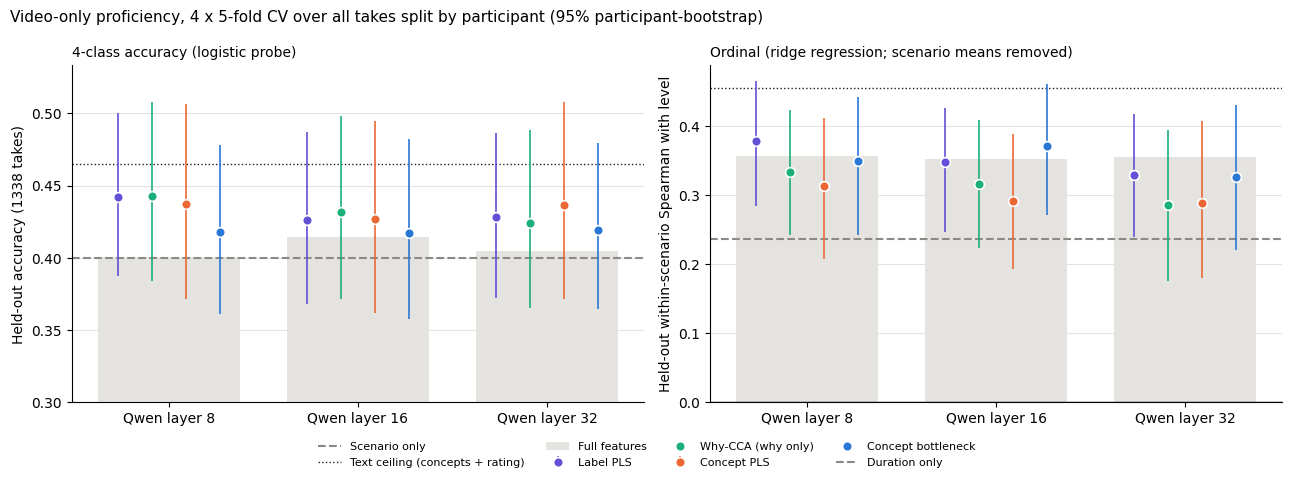

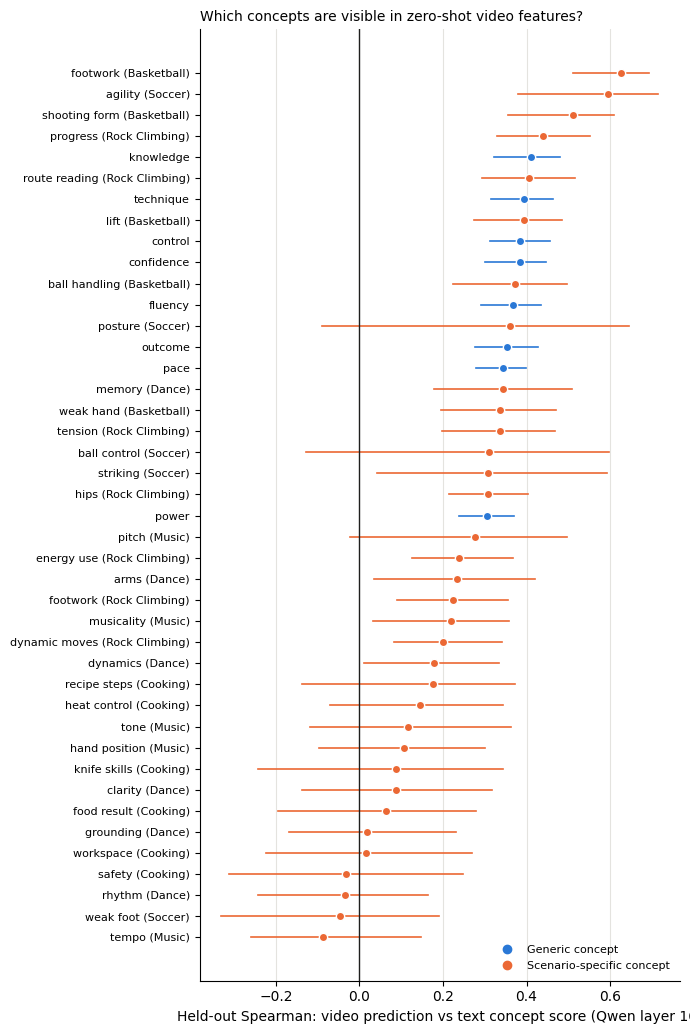

In [11]:
import matplotlib.pyplot as plt

COLORS = {"label PLS": "#6250d6", "why-CCA (why only)": "#1baf7a", "concept PLS": "#eb6834", "concept bottleneck": "#2a78d6"}
NULL_COLOR, GRID_COLOR, BAND_COLOR, DARK = "#8a8984", "#e4e3df", "#e4e3df", "#1f1f1d"

def style(ax, axis="y"):
    ax.grid(axis=axis, color=GRID_COLOR, lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

layers = list(LAYERS.values())
x = np.arange(len(layers))
all_rows = SUBGROUPS["All"]
fig, (ax, ax_rho) = plt.subplots(1, 2, figsize=(13, 4.4))
offsets = dict(zip(COLORS, np.linspace(-0.27, 0.27, len(COLORS))))
ax.bar(x, [per_take[f"layer {l}: full"].mean() for l in layers], width=0.75, color=BAND_COLOR, label="Full features")
ax.axhline(per_take["scenario only"].mean(), color=NULL_COLOR, lw=1.5, ls="--", label="Scenario only")
ax.axhline(per_take["text: concepts + rating"].mean(), color=DARK, lw=1, ls=":", label="Text ceiling (concepts + rating)")
for method, color in COLORS.items():
    stats = np.array([describe(per_take[f"layer {l}: {method}"], all_rows) for l in layers])
    ax.errorbar(x + offsets[method], stats[:, 0], yerr=[stats[:, 0] - stats[:, 1], stats[:, 2] - stats[:, 0]], ls="none",
                marker="o", ms=7, color=color, markeredgecolor="white", markeredgewidth=1.2, elinewidth=1.2, capsize=0,
                label=method[0].upper() + method[1:])
ax.set_ylabel(f"Held-out accuracy ({len(names)} takes)")
ax.set_ylim(0.3, None)
ax.set_title("4-class accuracy (logistic probe)", loc="left", fontsize=10)

ax_rho.bar(x, [ordinal_stats[f"layer {l}: full"][0][0] for l in layers], width=0.75, color=BAND_COLOR)
ax_rho.axhline(ordinal_stats["duration only"][0][0], color=NULL_COLOR, lw=1.5, ls="--", label="Duration only")
ax_rho.axhline(ordinal_stats["text: concepts + rating"][0][0], color=DARK, lw=1, ls=":")
for method, color in COLORS.items():
    stats = np.array([ordinal_stats[f"layer {l}: {method}"][0] for l in layers])
    ax_rho.errorbar(x + offsets[method], stats[:, 0], yerr=[stats[:, 0] - stats[:, 1], stats[:, 2] - stats[:, 0]], ls="none",
                    marker="o", ms=7, color=color, markeredgecolor="white", markeredgewidth=1.2, elinewidth=1.2, capsize=0)
ax_rho.axhline(0, color=DARK, lw=1)
ax_rho.set_ylabel("Held-out within-scenario Spearman with level")
ax_rho.set_title("Ordinal (ridge regression; scenario means removed)", loc="left", fontsize=10)
for a in (ax, ax_rho):
    a.set_xticks(x, [f"Qwen layer {l}" for l in layers])
    style(a)
handles, labels = ax.get_legend_handles_labels()
handles_rho, labels_rho = ax_rho.get_legend_handles_labels()
fig.legend(handles + handles_rho, labels + labels_rho, frameon=False, fontsize=8, ncol=4, loc="upper center",
           bbox_to_anchor=(0.5, 0.02))
fig.suptitle(f"Video-only proficiency, {N_REPEATS} x {N_FOLDS}-fold CV over all takes split by participant "
             "(95% participant-bootstrap)", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig("figures/why_concepts_accuracy.png", dpi=200, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 0.22 * len(COLUMNS) + 1.2))
y = np.arange(len(COLUMNS))[::-1]
for row, column in zip(y, order):
    rho, lo, hi = visibility[16, column]
    color = "#2a78d6" if COLUMNS[column][0] == "all" else "#eb6834"
    ax.plot([lo, hi], [row, row], color=color, lw=1.2)
    ax.plot(rho, row, "o", color=color, ms=6, markeredgecolor="white", markeredgewidth=1)
ax.set_yticks(y, [f"{COLUMNS[c][1]}" + ("" if COLUMNS[c][0] == "all" else f" ({COLUMNS[c][0]})") for c in order], fontsize=8)
ax.axvline(0, color=DARK, lw=1)
ax.set_xlabel("Held-out Spearman: video prediction vs text concept score (Qwen layer 16)")
ax.plot([], [], "o", color="#2a78d6", label="Generic concept")
ax.plot([], [], "o", color="#eb6834", label="Scenario-specific concept")
ax.legend(frameon=False, fontsize=8, loc="lower right")
style(ax, "x")
ax.set_title("Which concepts are visible in zero-shot video features?", loc="left", fontsize=10)
fig.tight_layout()
fig.savefig("figures/why_concepts_visibility.png", dpi=200, bbox_inches="tight")
plt.show()